# Code a Chip Together, with Viaduct: A Designer and an AI Agent in One Live EDA Session
### One live bridge between an AI agent, the designer and the open-source EDA tools: interrupts, time scroll and cockpit, shown on a SKY130 five-transistor OTA, a two-stage op amp and a T-coil bandwidth extension

| Name                    | Affiliation                                                                                          | IEEE Member | SSCS Member | Email |
|:-----------------------:|:----------------------------------------------------------------------------------------------------:|:-----------:|:-----------:|:-----:|
| AXi Supeng*             | Institute of Microelectronics, A*STAR, Singapore; Nanyang Technological University, Singapore        | Yes         | No          |AXIS0001@e.ntu.edu.sg|
| Jinhai Hu* (Leader)     | Institute of Microelectronics, A*STAR, Singapore                                                     | Yes         | Yes         |hujh@a-star.edu.sg|
| Zhishuai Zhang          | ETH Zürich, Switzerland                                                                              | Yes         | Yes         |zzhishuai@ethz.ch|
| Wang Ling Goh (Advisor) | Nanyang Technological University, Singapore                                                          | Yes         | Yes         |ewlgoh@ntu.edu.sg|
| Yuan Gao (Advisor)      | Institute of Microelectronics, A*STAR, Singapore                                                     | Yes         | Yes         |gaoy@a-star.edu.sg|

**PDK:** SkyWater SKY130 (open) · **Tools:** IIC-OSIC-TOOLS image (versions printed below)

Viaduct lets an LLM agent (Claude Code, Codex) or a notebook drive the KLayout and xschem windows a
designer is watching, and run ngspice, FastHenry, FasterCap, Palace and the KLayout DRC/LVS decks as
batch jobs, through one Python API, a CLI and an MCP server. Its point is that **the designer stays in
the loop**: they watch the agent work in their own windows, and can edit by hand, give an instruction
about what they have selected, pause the agent or go back to any earlier step at any moment. The agent
is interrupted with the exact change and continues from the designer's version. This notebook uses the
same API in **headless** mode: the same tools and the same in-process taps, on an invisible display.

**How to run.** Inside the IIC-OSIC-TOOLS container (Jupyter mode, or `jupyter lab` from the desktop's
terminal), open `/foss/designs/viaduct/viaduct_code_a_chip.executed.ipynb` and run all cells.
All three parts run in about 5 minutes; the optional full-wave run (C4) takes 20-50 minutes and is
off by default.

| Part | Case study | Shows |
|---|---|---|
| A | **The designer in the loop** | the demo video of a live session, then every way a designer steps in: a hand edit in the window, an instruction about a selection, a pause, a restore from the time scroll, and the rebuild guard that protects their work. Each one interrupts the agent with the exact change |
| B | **The same on a larger design**: a two-stage op amp | the agent builds a two-stage Miller op amp and sweeps its compensation; mid-sweep the designer edits two devices by hand, sends an instruction about the compensation network, and restores back and forward. The time scroll as pictures, and a pass/fail check of each function |
| C | T-coil bandwidth extension: layout and EM | a layout PCell edited in KLayout through the API, FastHenry / FasterCap / DRC, closed loop from ideal T-coil to a sized and extracted coil, full-wave cross-check |

## 0. Environment

In [1]:
import os, sys, json, subprocess, platform
ROOT = os.getcwd()                    # the repository root, also when run from runs/notebook/
while not os.path.exists(os.path.join(ROOT, "client.py")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, "examples"))
from viaduct import Viaduct, __version__
def ver(cmd):
    try:
        return subprocess.run(["bash", "-lc", cmd], capture_output=True, text=True, timeout=60).stdout.strip().splitlines()[-1]
    except Exception as e:
        return repr(e)
versions = {
    "viaduct": __version__,
    "image": os.environ.get("IIC_OSIC_TOOLS_VERSION"),
    "klayout": ver("klayout -v"),
    "xschem": ver("xschem -v 2>&1 | grep -m1 -i 'xschem v'"),
    "ngspice": ver("ngspice -v 2>&1 | grep -m1 ngspice"),
    "fasthenry": ver("fasthenry 2>&1 | grep -m1 -i fasthenry"),
    "FasterCap": ver("FasterCap -bv 2>&1 | head -1"),
    "python": platform.python_version(),
}
print(json.dumps(versions, indent=2))

{
  "viaduct": "0.3.0",
  "image": "2026.08",
  "klayout": "KLayout 0.30.11",
  "xschem": "XSCHEM V3.4.8RC",
  "ngspice": "** ngspice-47 : Circuit level simulation program",
  "fasthenry": "Running FastHenry 3.0.1 (28May12)",
  "FasterCap": "Running FasterCap version 6.0.7",
  "python": "3.12.3"
}


## 1. The designer stays in charge: what Viaduct adds
In real analog design the designer is not optional. Specifications, topology, trade-offs, layout
intent and sign-off are judgement calls, and an agent that works alone in a private container hands
back files after the fact, with no way to steer it half way. Viaduct takes the other route: **the agent
works in the designer's own session**, like a colleague at the same Virtuoso screen.

| Interaction | Without Viaduct | With Viaduct |
|---|---|---|
| Where the agent works | its own container; results arrive as files afterwards | the KLayout and xschem windows the designer is watching; every edit is drawn as it happens |
| Steering | stop the run, edit the prompt, start again | the designer can watch, interrupt, hand-edit or select an instance and say "resize this"; the agent reads the designer's edits and selection back |
| Undo | regenerate | every edit is a step in the time scroll; the designer restores any of them, and an agent batch in KLayout is one Ctrl+Z |
| The designer's work | not shared, so not at risk, but not used either | protected: dialogs stay the designer's (never clicked away), a schematic they edited cannot be rebuilt, unsaved work is not discarded, one write lock per tool |
| Evidence | logs to read | numbers with run IDs, screenshots after edits, connectivity and bias checks with plain warnings, RF results written into the PCell next to the run that produced them |
| Failure | silent or a crash | timeouts report the blocking dialog and an ID whose outcome can be looked up; nothing is executed twice; replies are signed; every request is audited |
| Control | whatever the agent's shell allows | safe mode restricts the agent to structured operations, no raw code |

### How the designer takes part, and what it does to the agent
| The designer... | How | What the agent gets | Effect |
|---|---|---|---|
| **watches** | their own xschem / KLayout windows; the cockpit page beside them shows the agent's status, plan and time scroll | nothing to do | every edit is visible as it happens, not as a log afterwards |
| **edits by hand** | mouse and keyboard in the window; Viaduct is not told | its next edit is refused, `INTERRUPTED`, with the exact change (`M5: L 1 -> 2`) | the agent continues from the designer's version instead of overwriting it |
| **gives an instruction** | one sentence in the cockpit (or `interrupts.send`); the current selection is attached | the message plus the selection, e.g. `{"xschem": ["M1", "M2"]}` | "resize these" without naming instances or stopping the run |
| **pauses** | Pause in the cockpit | its edits stay blocked until Resume; reads still work | the designer can check something without racing the agent |
| **goes back** | Restore on any step of the time scroll | a restore interrupt listing every change it reverted | trying an idea costs nothing; the replaced state is recorded first |
| **is protected** | nothing to do | rebuilding a schematic the designer edited is `DENIED`, with a hint | the agent cannot erase the designer's work by regenerating it |

The split of work that follows: **the designer decides, the agent does the legwork** (placing and wiring
dozens of elements, running sweeps and testbenches, DRC loops, EM runs, bookkeeping) and **surfaces
what needs a decision**. Section 3 shows the bridge itself: one request to each tool, and what the
agent sees of it. Part A shows the designer stepping in; part B checks that it still holds on a
larger design with a sweep running; part C shows the layout side on a T-coil; the table at the end
summarizes who did what. The same API also runs headless, which is how
this notebook runs, so an interactive session can be turned into a reproducible record.

## 2. Architecture
```
designer ── xschem / KLayout windows ──────────────┐   (hand edits, selection, dialogs stay theirs)
designer ── cockpit page (status, instruction, ─┐  │
            pause, plan, time scroll, restore)  │  │
agent / notebook ── Viaduct API · CLI · MCP ── relay (lock, sign, receipts, audit, timeouts,
                                               │      interrupts, time scroll, rebuild guard)
                                               ├─ KLayout tap  (on KLayout's Qt main thread)   live layout edits, readback, screenshots
                                               ├─ xschem tap   (on xschem's Tk event loop)     live schematic edits, pin-level wiring, connectivity check
                                               ├─ ngspice runner   (.raw parser, AC/tran metrics, per-device operating point, sweeps)
                                               ├─ FastHenry / FasterCap / Palace runners   (L, R, Q, k; parasitic C; full wave)
                                               └─ DRC runner (SKY130 KLayout deck)         LVS through the PDK's KLayout deck
```
Live mode targets the designer's noVNC desktop; headless mode starts the same tools on Xvfb with their own ports.

In [2]:
vd = Viaduct.from_env(mode="headless")
st = vd.start().check().result
print("klayout: %s, xschem: %s" % (st["klayout"], st["xschem"]))
for tool, ds in (st.get("dialogs") or {}).items():
    for d in ds:                      # KLayout's start-up "Tip" in headless mode; left alone, dialogs are the designer's
        print("open dialog in %s: %r (not touched)" % (tool, d["title"]))
# a fresh demo session: acknowledge anything an earlier run left pending (see part A)
vd.interrupts.status(); vd.interrupts.ack("all"); vd.interrupts.resume()

klayout: already running, xschem: already running
open dialog in klayout: 'Tip' (not touched)


Result(status='SUCCESS', result={'paused': False}, error=None, ms=43.3, extra={'request_id': '25ca509ce973495ab70e51ef15d9c024'})

## 3. The bridge: one API from the agent to every tool
Without Viaduct an agent would need a different way into each tool: Tcl typed into xschem, Python inside
KLayout, netlists and `.raw` files for ngspice, input decks and text output for FastHenry, a DRC deck
and an XML report. Viaduct puts **one request / reply shape** in front of all of them, the way a
Virtuoso session gives the designer one environment for schematic, layout, ADE and Calibre.

| Tool | How Viaduct reaches it | What the agent sends | What comes back |
|---|---|---|---|
| xschem | a tap **inside** the running xschem (Tk event loop): edits are drawn in the designer's window | place / wire by pin name / set props, in one batch | per-edit results, connectivity read back, a time-scroll step |
| KLayout | a tap **inside** the running KLayout (Qt main thread) | new layout, PCell place / re-parameterize, shapes | bounding box and PCell parameters read back, one undo step |
| ngspice | batch runner on the netlist xschem writes | operating point, AC / tran, sweeps | per-device bias with plain warnings, AC metrics, plots, a run ID |
| FastHenry / FasterCap / Palace | batch runners on the PCell's geometry | the PCell parameters | L, R, Q, k per frequency; parasitic C; a run ID, written into the PCell |
| DRC | the PDK's KLayout deck on the open layout | nothing but "check" | violations per rule, markers shown in KLayout, a run ID |

Every reply has the same fields: `status` (`SUCCESS`, `ERROR`, `TIMEOUT`, `DENIED`, `INTERRUPTED`), the
`result`, the time it took and a `request_id` whose outcome can be looked up later. The cell below sends
one request to each tool through that API: the agent builds a small common-source amplifier in xschem,
checks and simulates it, places a T-coil in KLayout, and runs FastHenry and DRC on it.

In [3]:
import glob, time
from IPython.display import Image, Markdown, display
for f in glob.glob(os.path.join(ROOT, "xschem", "tour_cs_*.sch")):
    os.remove(f)
TOUR = os.path.join(ROOT, "xschem", "tour_cs_%s.sch" % time.strftime("%Y%m%d_%H%M%S"))
tour = []
def log(tool, request, r, value):
    r.check()
    res = r.result if isinstance(r.result, dict) else {}
    ref = res.get("run_id") or ("step %s" % r.extra["history_step"] if "history_step" in r.extra else "")
    tour.append((tool, request, r.status, "%.0f" % r.ms, ref, value(res)))
    return res

b = vd.xschem.batch()                 # xschem, live: placed and wired by pin name, one redraw
b.add("new_schematic", path=TOUR)
b.place("sky130_fd_pr/nfet_01v8.sym", 0, 0, name="M1", W="2", L="0.15", nf="1")
b.place("res.sym", 20, -100, name="R1", value="10k")
b.place("capa.sym", 180, -20, name="CL", value="50f")
b.place("vsource.sym", -260, -60, name="VDD", value="1.8")
b.place("vsource.sym", -160, -60, name="VIN", value="dc 0.9 ac 1")
b.wire_pins("R1", "M", "M1", "D")
b.wire(20, -50, 180, -50, 240, -50)
b.place("lab_pin.sym", 240, -50, rot=2, lab="OUT")
for inst, pin, net in [("R1", "P", "VDD"), ("M1", "G", "IN"), ("M1", "S", "GND"), ("M1", "B", "GND"), ("CL", "m", "GND"),
                       ("VDD", "p", "VDD"), ("VDD", "m", "GND"), ("VIN", "p", "IN"), ("VIN", "m", "GND")]:
    b.label_pin(inst, pin, net)
b.place("sky130_fd_pr/corner.sym", -260, 120, corner="tt")
b.place("devices/code_shown.sym", 120, 120, name="NGSPICE", only_toplevel="true",
        value=".control\nsave all\nop\nac dec 20 1e5 1e11\nwrite tour_cs.raw\n.endc")
log("xschem", "build a common-source amplifier (%d edits, one batch)" % len(b.ops), b.run(),
    lambda res: "%d / %d edits done" % (res["done"], res["total"]))
log("xschem", "connectivity check", vd.xschem.check(),
    lambda res: "%d nets, %d warnings" % (res["nets"], len(res["warnings"])))
log("ngspice", "DC operating point of every MOSFET", vd.sim.op(),
    lambda res: "M1: Id %.0f uA, gm/Id %.1f, %s" % (res["devices"]["M1"]["id_ua"], res["devices"]["M1"]["gm_id"],
                                                  res["devices"]["M1"]["region"]))
log("ngspice", "AC of the schematic, node out", vd.sim.xschem(nodes=["out"], live=False),
    lambda res: "gain %.1f dB, f3dB %.2f GHz" % (res["raw_files"][0]["plots"][0]["nodes"]["out"]["dc_gain_db"],
                                                 res["raw_files"][0]["plots"][0]["nodes"]["out"]["f3db_hz"] / 1e9))
kb = vd.klayout.batch()               # KLayout, live: one request, one undo step
kb.new_layout("TOUR")
kb.place_tcoil("L1", params={"metalWidth": 3.0, "area": 5000.0})
log("KLayout", "new layout + T-coil PCell (one batch)", kb.run(), lambda res: "%d / %d ops done" % (res["done"], res["total"]))
log("KLayout", "read the PCell back", vd.klayout.describe("L1"),
    lambda res: "%.0f x %.0f um, turn spacing %.2f um" % (res["bbox_um"][1][0] - res["bbox_um"][0][0],
                                                       res["bbox_um"][1][1] - res["bbox_um"][0][1], res["params"]["actualTurnSpacing"]))
log("FastHenry", "L, Q, k of that coil at 10 GHz", vd.em.fasthenry({"metalWidth": 3.0, "area": 5000.0}, freqs_hz=[1e10], mesh="coarse"),
    lambda res: "L1 %.0f pH, Q1 %.1f, K %+.2f" % (res["results"][0]["L1_nH"] * 1e3, res["results"][0]["Q1"], res["results"][0]["K1"]))
log("DRC", "SKY130 deck on the open layout", vd.verify.drc(),
    lambda res: "%d rules checked, %d violations" % (res["rules_checked"], res["violations"]))

display(Markdown("| Tool | Request | Status | ms | Run ID / step | What came back |\n|---|---|---|---|---|---|\n" +
                 "\n".join("| " + " | ".join(map(str, t)) + " |" for t in tour)))

| Tool | Request | Status | ms | Run ID / step | What came back |
|---|---|---|---|---|---|
| xschem | build a common-source amplifier (20 edits, one batch) | SUCCESS | 207 | step 654 | 20 / 20 edits done |
| xschem | connectivity check | SUCCESS | 58 |  | 4 nets, 0 warnings |
| ngspice | DC operating point of every MOSFET | SUCCESS | 3169 | 20261029_110451_b03c | M1: Id 82 uA, gm/Id 7.9, saturation |
| ngspice | AC of the schematic, node out | SUCCESS | 4062 | 20261029_110454_8a85 | gain 13.1 dB, f3dB 0.41 GHz |
| KLayout | new layout + T-coil PCell (one batch) | SUCCESS | 271 | step 655 | 2 / 2 ops done |
| KLayout | read the PCell back | SUCCESS | 59 |  | 62 x 71 um, turn spacing 2.27 um |
| FastHenry | L, Q, k of that coil at 10 GHz | SUCCESS | 778 | 20261029_110458_c31b | L1 160 pH, Q1 7.2, K -0.34 |
| DRC | SKY130 deck on the open layout | SUCCESS | 6526 | 20261029_110459_e8d7 | 256 rules checked, 0 violations |

Both GUI tools were edited live (in this notebook on the headless display, in a live session in the
designer's windows); the screenshots are each tool's own rendering, taken through the same API.

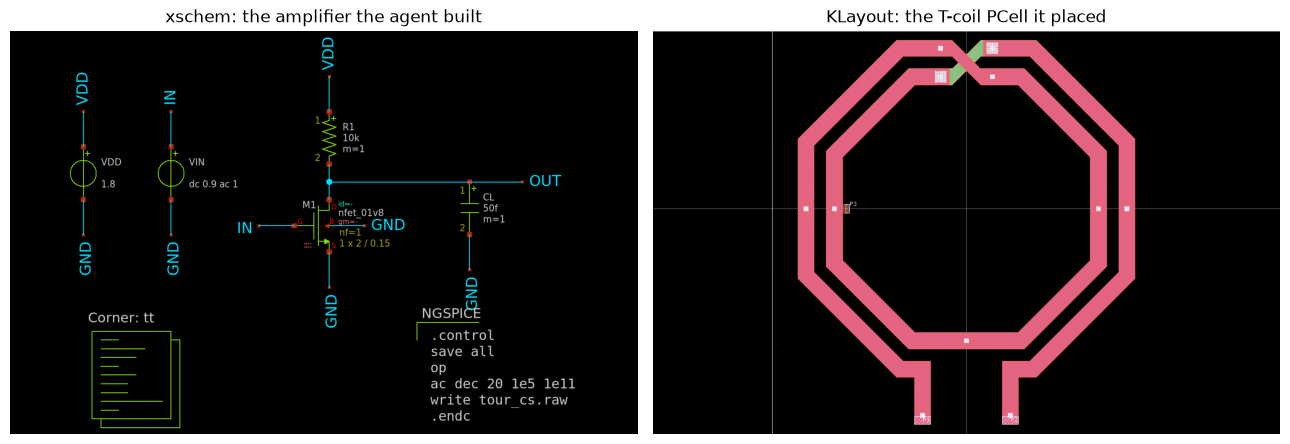

In [4]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
vd.xschem.zoom_fit(); vd.klayout.zoom_fit()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, tool, title in zip(axs, (vd.xschem, vd.klayout), ("xschem: the amplifier the agent built", "KLayout: the T-coil PCell it placed")):
    ax.imshow(mpimg.imread(tool.screenshot().check().result["local_path"])); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

### The agent's side of the bridge
An agent (Claude Code, Codex, or a local model) does not import Python: it connects to Viaduct's **MCP
server** (`python -m viaduct.mcp_server`) and sees each operation as a tool with a description and an
input schema. `AGENTS.md` and the per-tool notes in `skills/` tell it the working rules (build in one
batch, check before simulating, never close the designer's dialogs, report numbers with run IDs). The
MCP tools are thin wrappers of the same API, so a call from the agent returns exactly what the
notebook gets. The cell lists the tools and makes one MCP call the way an agent would.

In [5]:
from viaduct.mcp_server import TOOLS, handle
about = {"viaduct": "session and designer: status, dialogs, receipts, interrupts, plan, time scroll, audit",
         "xschem": "schematic, live", "klayout": "layout, live", "sim": "ngspice",
         "em": "FastHenry / FasterCap / Palace", "verify": "DRC"}
groups = {}
for name in TOOLS:
    groups.setdefault(name.split("_")[0], []).append(name)
print("%d MCP tools" % len(TOOLS))
for g, names in groups.items():
    print("  %-8s %2d  %s" % (g, len(names), about.get(g, "")))
print()
print("what the agent reads about sim_op:", TOOLS["sim_op"][0][:160], "...")
reply = handle(vd, {"jsonrpc": "2.0", "id": 1, "method": "tools/call", "params": {"name": "sim_op", "arguments": {}}})
got = json.loads(reply["content"][0]["text"])
print("what it gets back:", json.dumps({"isError": reply["isError"], "status": got["status"], "request_id": got["request_id"],
                                        "run_id": got["result"]["run_id"], "M1": {k: got["result"]["devices"]["M1"][k]
                                        for k in ("id_ua", "gm_us", "vds_margin", "region")},
                                        "warnings": got["result"]["warnings"]}, indent=1))

52 MCP tools
  viaduct  12  session and designer: status, dialogs, receipts, interrupts, plan, time scroll, audit
  klayout  14  layout, live
  xschem   17  schematic, live
  sim       4  ngspice
  em        4  FastHenry / FasterCap / Palace
  verify    1  DRC

what the agent reads about sim_op: DC operating point of every MOSFET: Id, gm, gds, Vgs, Vds, Vth, Vdsat, |Vds|-Vdsat margin, region (saturation / edge / triode), gm/Id, gm/gds. Without netlist:  ...


what it gets back: {
 "isError": false,
 "status": "SUCCESS",
 "request_id": "b3a6f0eea28d40218dd34a87cbe690c9",
 "run_id": "20261029_110507_6d07",
 "M1": {
  "id_ua": 82.163,
  "gm_us": 646.586,
  "vds_margin": 0.8323,
  "region": "saturation"
 },
 "warnings": []
}


## 4. Demo video: the designer interrupts the agent (2 min 27 s)
<video src="viaduct_code_a_chip_together.mp4" controls width="100%"></video>

Recorded live in the IIC-OSIC-TOOLS desktop: xschem top left, the agent's terminal below it, the
cockpit on the right. The designer edits M5 by hand, sends an instruction with M1/M2 selected,
and restores an earlier step; each one interrupts the agent with the exact change (part A below
runs the same steps headless). If no player shows (GitHub's preview does not play video), open
[viaduct_code_a_chip_together.mp4](viaduct_code_a_chip_together.mp4).

---
# Part A. The designer in the loop: interrupts and the time scroll

An agent is useful in analog design only if the designer can step in at any moment, and the agent
notices, adapts and keeps going **from the designer's version**, not from its own plan. In a pilot run
without this, a designer's edit was overwritten three seconds later when the agent rebuilt the
schematic from its script.

Viaduct treats the designer's commands like interrupts on a CPU:

| CPU | Viaduct |
|---|---|
| a device raises an IRQ | the designer edits by hand, sends an instruction, pauses, or restores an earlier step |
| the CPU stops at the next instruction boundary | the agent's next **edit** returns `INTERRUPTED` and changes nothing (reads still work) |
| context save | the agent's plan (its remaining steps) and a time-scroll checkpoint |
| interrupt service routine, EOI | the agent reads the exact change or instruction, acknowledges (`interrupt-ack`), applies it |
| interrupt mask | a pause blocks the agent until the designer resumes |

The cells below play both roles: `vd` is the agent, `designer` is a Viaduct instance whose requests are
attributed to the designer. In live mode (the video above) the designer uses the windows and the
**cockpit** page (`python client.py cockpit`) instead.

## A1. The agent builds the OTA; every edit is a step in the time scroll
The agent builds a five-transistor OTA (49 edits in one batch, wired by pin name; its sizes come from an
L sweep in `examples/ota5t_sweep.py`) and works on a copy of it. Each successful edit through Viaduct stores
the design as it is in memory (unsaved edits included), a screenshot and who made it. The agent saves
its plan; the designer sees it in the cockpit and the agent gets it back with every interrupt.

agent: 49 edits in one batch, connectivity ok, gain 41.9 dB


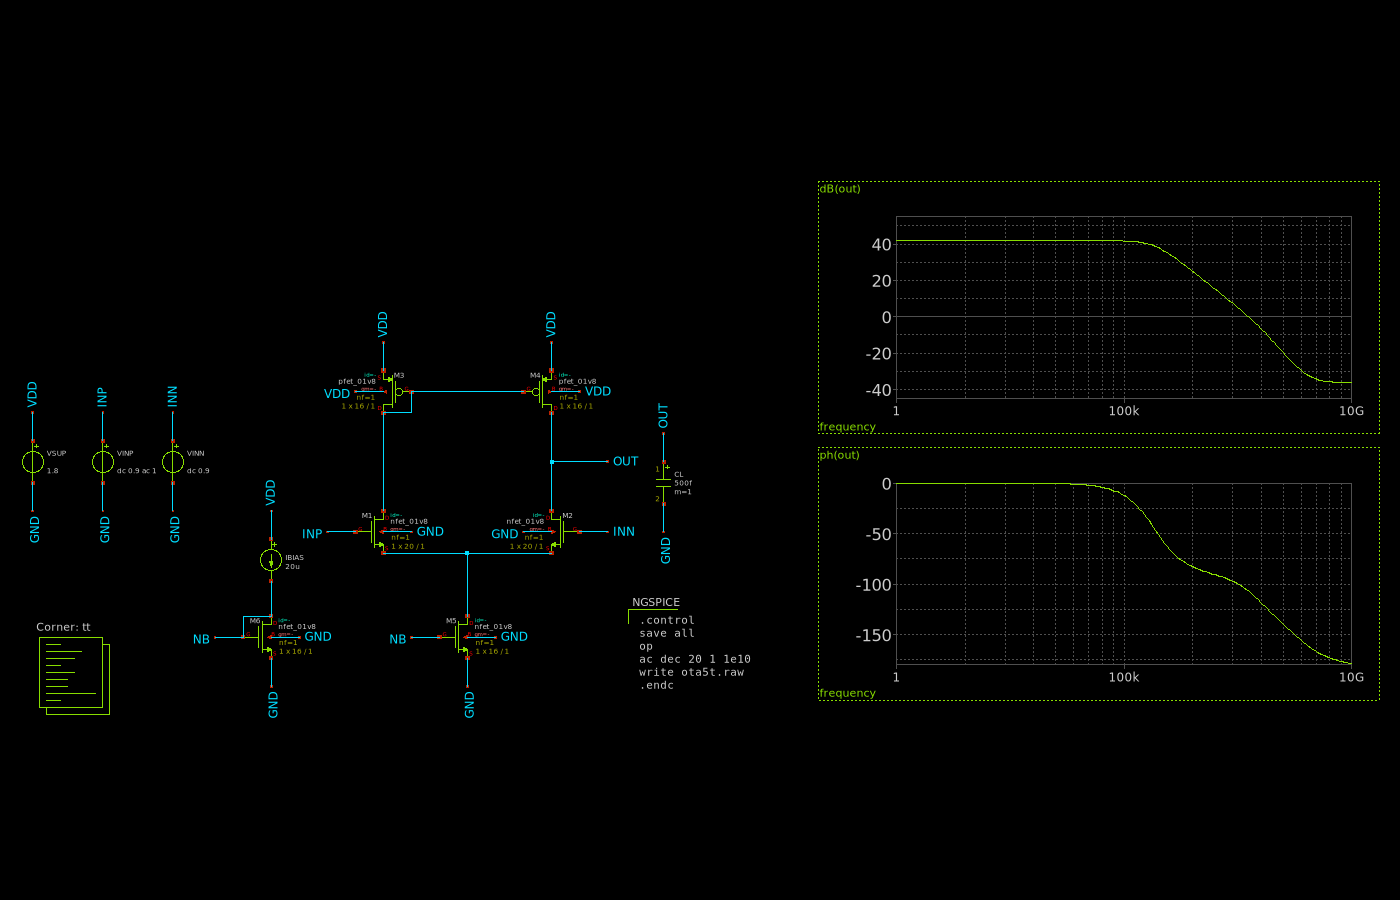

checkpoint 659 | M5 W=16 L=1 | M1 W=20 L=1
#658  agent    edit        xschem.modify
#659  designer checkpoint  before the designer steps in


In [6]:
import glob, shutil, time, re
from IPython.display import Image, display
import ota5t_xschem as ota
built = ota.run(vd, ota.parse(["--replace"]))
print("agent: %d edits in one batch, connectivity %s, gain %.1f dB" % (built["build_ops"], built["check"], built["dc_gain_db"]))
display(Image(built["screenshot"], width=900))

designer = Viaduct.from_env(mode="headless", actor="designer")
for old in glob.glob(os.path.join(ROOT, "xschem", "ota5t_designer*.sch")):
    os.remove(old)                  # copies from earlier runs
# a fresh copy per run, so part A's history holds only this run's steps; the agent's file stays rebuildable
OTA_C = os.path.join(ROOT, "xschem", "ota5t_designer_%s.sch" % time.strftime("%Y%m%d_%H%M%S"))
shutil.copy(os.path.join(ROOT, "xschem", "ota5t.sch"), OTA_C)
x = vd.xschem
start_step = x.modify(OTA_C).check().extra["history_step"]   # part A's history starts here
vd.interrupts.plan(steps=["review bias", "size the pair for gain", "simulate", "layout"], done=1).check()
ref = designer.history.checkpoint("before the designer steps in").check().result["step"]
def props(name):
    return [i for i in x.describe().check().result["instances"] if i["name"] == name][0]["props"]
def wl(name):
    p = props(name)
    return "W=%s L=%s" % (re.search(r"\bW=(\S+)", p).group(1), re.search(r"\bL=(\S+)", p).group(1))
print("checkpoint", ref, "| M5", wl("M5"), "| M1", wl("M1"))
for s in vd.history.list(4).check().result["steps"]:
    if s["step"] >= start_step:
        print("#%-4d %-8s %-11s %s" % (s["step"], s["actor"], s["kind"], s["op"] or s["label"]))

## A2. A hand edit in the window interrupts the agent
The designer lengthens the tail source M5 directly in xschem. That edit does not go through Viaduct;
the cell below makes it the same way a mouse edit would, by talking to xschem behind the relay.
Viaduct notices it on the agent's next request from a fingerprint of the design, records it as a
designer step, and refuses the agent's edit with the exact change.

In [7]:
sys.path.insert(0, os.path.join(ROOT, "container"))
import relay as _relay                      # stands in for the designer's mouse: bypasses Viaduct
_relay.STATE_DIR = os.path.expanduser("~/.viaduct/headless")
_relay._xschem("eval", {"code": "xschem setprop instance M5 L 2; xschem setprop instance M5 W 32"}, 10)

r = x.set_props("M1", L="1.5")               # the agent carries on with its plan
print(r.status, "-", r.error)
for i in r.extra["interrupts"]:
    print("  #%d %s at step %s: %s" % (i["id"], i["kind"], i.get("step"), json.dumps(i.get("changes"))))
print("agent's plan returned with it:", r.extra["plan"]["steps"], "done", r.extra["plan"]["done"])
print("M1 unchanged:", wl("M1"))

INTERRUPTED - the designer has 1 unacknowledged interrupt(s); nothing was changed
  #99 hand_edit at step 660: {"changed": {"M5": {"L": ["1", "2"], "W": ["16", "32"]}}}
agent's plan returned with it: ['review bias', 'size the pair for gain', 'simulate', 'layout'] done 1


M1 unchanged: W=20 L=1


## A3. An instruction with a selection, then acknowledge and continue
The designer also selects the input pair and asks for a longer L. (From the cockpit the current
selection is attached automatically; here it is given explicitly.) The agent reads both interrupts,
acknowledges them with a note, applies the instruction on top of the designer's M5 and checks the bias.

In [8]:
designer.interrupts.send("Make the pair M1/M2 L = 1.5 um, keep W/L; then continue",
                         selection={"xschem": ["M1", "M2"]}).check()
pending = vd.interrupts.status().check().result["pending"]
for i in pending:
    print("#%d %-12s %s %s" % (i["id"], i["kind"], i.get("message", ""), i.get("selection") or i.get("changes")))
print(vd.interrupts.ack("all", note="keeping M5 = 32/2; pair to 30/1.5").check().result)

with x.batch() as b:                         # paired devices in one batch
    b.add("set_props", name="M1", props={"W": "30", "L": "1.5"})
    b.add("set_props", name="M2", props={"W": "30", "L": "1.5"})
vd.interrupts.plan(done=2).check()
print("M1", wl("M1"), "| M2", wl("M2"), "| M5 (designer's)", wl("M5"))
op = vd.sim.op().check().result
for d in ("M1", "M2", "M5"):
    v = op["devices"][d]
    print("%-3s Id %6.2f uA  Vds margin %+.3f V  %s" % (d, v["id_ua"], v["vds_margin"], v["region"]))
print("warnings:", op["warnings"] or "none")

#99 hand_edit     {'changed': {'M5': {'L': ['1', '2'], 'W': ['16', '32']}}}
#100 instruction  Make the pair M1/M2 L = 1.5 um, keep W/L; then continue {'xschem': ['M1', 'M2']}


{'acknowledged': [99, 100], 'still_pending': [], 'paused': False}


M1 W=30 L=1.5 | M2 W=30 L=1.5 | M5 (designer's) W=32 L=2


M1  Id  14.10 uA  Vds margin +0.325 V  saturation
M2  Id  14.10 uA  Vds margin +0.325 V  saturation
M5  Id  28.20 uA  Vds margin +0.112 V  saturation
warnings: none


## A4. A pause: the designer holds the agent
The designer wants to look at something without the agent changing the design meanwhile. A pause is an
instruction that also masks the agent: acknowledging it is not enough, its edits stay refused until the
designer resumes. Reads (describe, simulate) still work while paused.

In [9]:
designer.interrupts.send("Hold on, I am checking the load mirror", pause=True).check()
r = x.set_props("M3", W="16")
print("agent edit             :", r.status, "-", r.error)
vd.interrupts.ack("all", note="waiting for the designer").check()
r = x.set_props("M3", W="16")
print("after ack, still paused:", r.status, "-", r.error)
print("a read while paused    :", "M3", wl("M3"))
designer.interrupts.resume().check()
r = x.set_props("M3", W="16")
print("after the designer's resume:", r.status)

agent edit             : INTERRUPTED - the designer has 1 unacknowledged interrupt(s); nothing was changed


after ack, still paused: INTERRUPTED - the designer has paused the session
a read while paused    : M3 W=16 L=1


after the designer's resume: SUCCESS


## A5. The rebuild guard
Rebuilding from a script is the quickest way to lose the designer's work. A schematic the designer
has edited cannot be rebuilt with `new_schematic replace=True`; the agent has to edit it in place.

In [10]:
r = x.new_schematic(OTA_C, replace=True)
print(r.status, "-", r.error)
print("hint:", r.extra.get("hint"))
print("M5 still the designer's:", wl("M5"))

DENIED - the designer edited /foss/designs/viaduct/xschem/ota5t_designer_20261029_110517.sch (history steps [660]); rebuilding it with new_schematic replace=true would erase their work
hint: change the open schematic with set_props / place / wire instead; rebuild only if the designer agrees (force_rebuild=true)
M5 still the designer's: W=32 L=2


## A6. The designer goes back: a restore is an interrupt too
The designer restores the checkpoint from A1. The windows show that state again (the replaced state is
recorded first, nothing is lost), and the agent is told what changed under it.

In [11]:
res = designer.history.restore(ref).check().result
print("restored", ref, "as step", res["new_step"])
r = x.set_props("M1", L="1.5")
irq = [i for i in r.extra["interrupts"] if i["kind"] == "restore"][0]
print(r.status, "-", irq["message"])
print("change:", json.dumps(irq["changes"]))
vd.interrupts.ack("all", note="back at the checkpoint; will re-plan").check()
print()
for s in vd.history.list(30).check().result["steps"]:
    if s["step"] >= start_step:
        print("#%-4d %-8s %-14s %s" % (s["step"], s["actor"], s["kind"], s["op"] or s["label"]))
tl = vd.history.timeline().check().result
print()
print("timeline page:", tl.get("local_path") or tl["path"])

restored 659 as step 666
INTERRUPTED - the designer restored step 659; continue from it
change: {"changed": {"M1": {"L": ["1.5", "1"], "W": ["30", "20"]}, "M2": {"L": ["1.5", "1"], "W": ["30", "20"]}, "M5": {"L": ["2", "1"], "W": ["32", "16"]}}}

#658  agent    edit           xschem.modify
#659  designer checkpoint     before the designer steps in
#660  designer hand_edit      xschem: edited in the GUI
#661  designer checkpoint     interrupt: Make the pair M1/M2 L = 1.5 um, keep W/L; then continue
#662  agent    edit           xschem.batch
#663  designer checkpoint     interrupt: Hold on, I am checking the load mirror
#664  agent    edit           xschem.set_props
#665  viaduct  before_restore state before restore to 659
#666  viaduct  restore        restored step 659

timeline page: /foss/designs/viaduct/runs/timeline_headless.html


> **Designer's view.** Nothing the agent did here needed the designer to repeat themselves or to
> watch the chat: the hand edit was enough, the agent's reply named the exact values, and the agent
> continued on the designer's version. A pause held it without losing its plan; the rebuild guard kept
> it from erasing the designer's work; the time scroll keeps every state on both sides, so trying an
> idea costs nothing. In live mode the cockpit shows the same status, plan and steps next to the desktop.

**Part A in one sentence:** five ways for the designer to step in (hand edit, instruction with a
selection, pause, restore, and the guard on their work), each one turned into an interrupt that tells
the agent exactly what changed, and the agent always continuing from the designer's version.

---
# Part B. A two-stage op amp: the same interaction on a larger design

Part A used a five-transistor OTA so that every change is easy to read. Part B checks that the
designer's interaction still works when the design and the agent's task grow. The design is a
two-stage Miller op amp: the OTA of part A as the first stage, a PMOS common-source second stage, and a
Miller capacitor with a nulling resistor, built by `examples/opamp2s_xschem.py`. The agent is in the
middle of a multi-step plan with a compensation sweep running when the designer steps in.

| | Part A | Part B |
|---|---|---|
| circuit | 5T OTA: 5 transistors + bias | two-stage op amp: 7 transistors + bias, Miller C and nulling R |
| edits to build it | 49 | 68 |
| what the agent is doing | single edits | a sweep over dozens of simulations |
| designer's actions | one at a time, on one device | a hand edit of two devices at once, an instruction about two passives, a restore back and forward |

The testbench closes the loop for DC only (OUT to INN through 1 GH, INN at AC ground through 1 F), so
the bias is that of a unity-gain buffer while the AC response is the open-loop gain. B6 shows the time
scroll of this part as pictures and checks each function.

## B1. The agent builds the op amp and saves its plan
68 edits in one batch, wired by pin name, connectivity read back, then AC and the operating point of every
transistor. The first compensation is deliberately light (Cc = 0.5 pF, Rz = 2 kohm): sizing it is the next
step of the agent's plan.

agent: 68 edits in one batch, connectivity ok
gain 82.5 dB, UGF 43.9 MHz, phase margin (unity feedback) 32.5 deg, 181 uW
dev     Id uA    gm uS  Vds margin  region
M3       9.47    119.1      +0.995  saturation
M4       9.47    119.2      +1.005  saturation
M1       9.47    190.4      +0.365  saturation
M2       9.47    190.5      +0.355  saturation
M5      18.94    309.3      +0.132  saturation
M7      61.60    755.3      +0.765  saturation
M8      61.60    995.6      +0.797  saturation
M6      20.00    325.2      +0.563  saturation
warnings: none


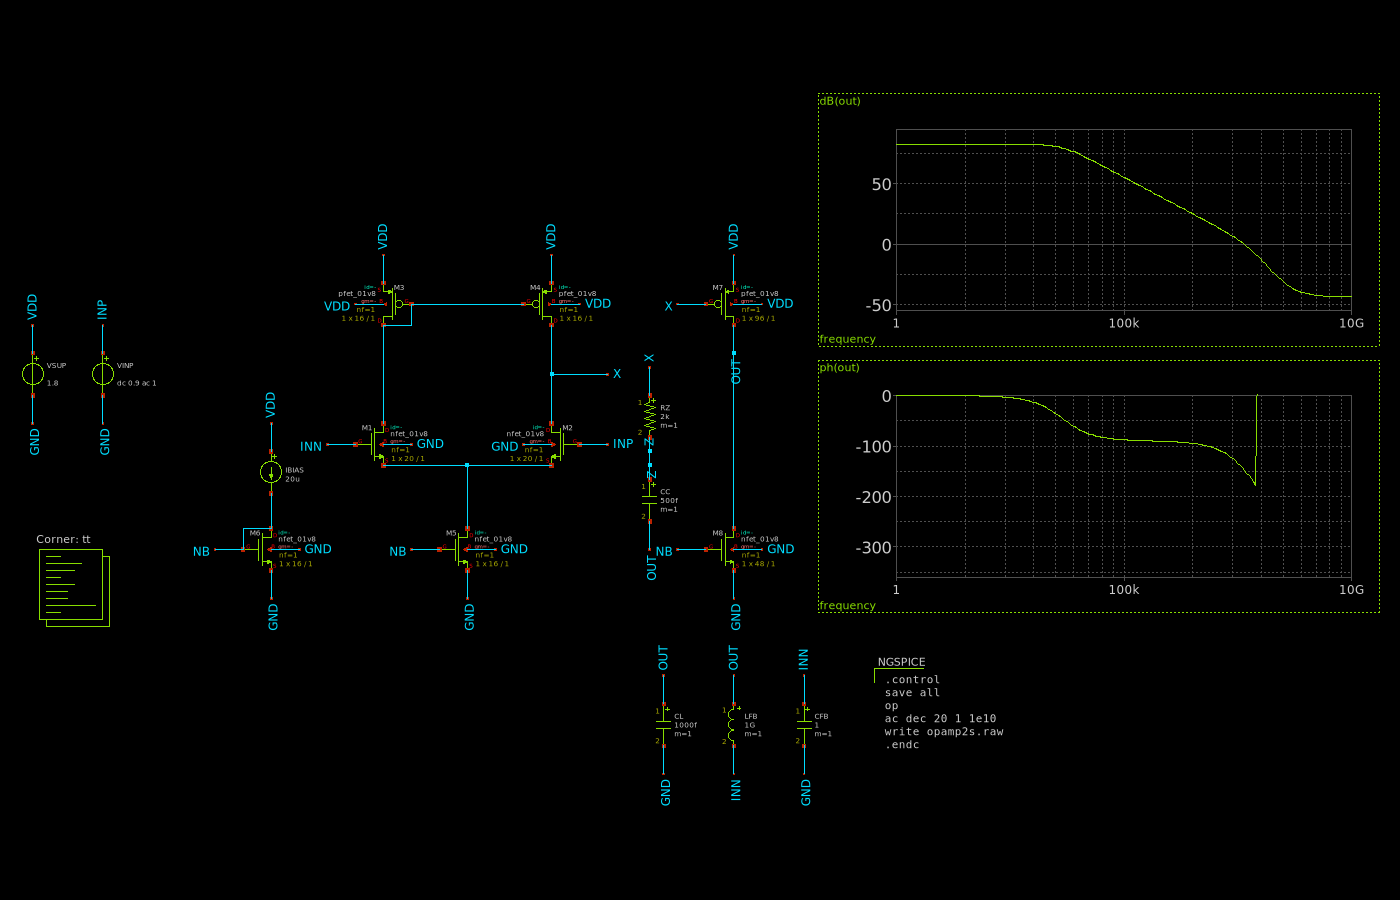

checkpoint 669 | M7 W=96  M8 W=48  CC=500f  RZ=2k


In [12]:
import opamp2s_xschem as o2
import numpy as np, matplotlib.pyplot as plt
for old in glob.glob(os.path.join(ROOT, "xschem", "opamp2s_*.sch")):
    os.remove(old)                  # files from earlier runs
OPAMP = os.path.join(ROOT, "xschem", "opamp2s_%s.sch" % time.strftime("%Y%m%d_%H%M%S"))
amp = o2.run(vd, o2.parse(["--out", OPAMP, "--cc-ff", "500", "--rz-k", "2"]))
print("agent: %d edits in one batch, connectivity %s" % (amp["build_ops"], amp["check"]))
print("gain %.1f dB, UGF %.1f MHz, phase margin (unity feedback) %.1f deg, %.0f uW" % (
    amp["dc_gain_db"], amp["ugf_hz"] / 1e6, amp["phase_margin_unity_fb_deg"], amp["power_uw"]))
def op_table(devices, warnings):
    print("%-4s %8s %8s %11s  %s" % ("dev", "Id uA", "gm uS", "Vds margin", "region"))
    for d, v in devices.items():
        print("%-4s %8.2f %8.1f %+11.3f  %s" % (d, v["id_ua"], v["gm_us"], v["vds_margin"], v["region"]))
    print("warnings:", warnings or "none")
op_table(amp["devices"], amp["bias_warnings"])
display(Image(amp["screenshot"], width=900))

b_start = vd.history.list(1).check().result["steps"][-1]["step"]          # part B's history starts here
vd.interrupts.plan(steps=["build the op amp", "compensate: sweep Cc and Rz", "check the bias", "characterize",
                          "layout"], done=1).check()
b_ref = designer.history.checkpoint("op amp as built by the agent").check().result["step"]
def val(name, key):
    return re.search(r"\b%s=(\S+)" % key, props(name)).group(1)
def stage2():
    return "M7 W=%s  M8 W=%s  CC=%s  RZ=%s" % (val("M7", "W"), val("M8", "W"), val("CC", "value"), val("RZ", "value"))
print("checkpoint", b_ref, "|", stage2())

## B2. The designer edits the second stage while the agent sweeps
The agent sweeps Cc, one point per edit and simulation. After its third point the designer, looking at
the slew rate, raises the second-stage current in the window: M8 from 48 to 64 um and M7 from 96 to 128 um
(the same ratio, so no systematic offset). Both are changed in one go, by hand, and Viaduct is not told.
The cell injects that edit between two of the agent's points, as if made with the mouse while the agent
was simulating.

In [13]:
def pm_point(cc_ff, rz_k):
    """one sweep point: CC and RZ in one batch, then a simulation; returns (reply to the edit, metrics or None)"""
    b = x.batch()
    b.add("set_props", name="CC", props={"value": "%gf" % cc_ff})
    b.add("set_props", name="RZ", props={"value": "%gk" % rz_k})
    r = b.run()                              # the reply as it is, INTERRUPTED included
    if r.status != "SUCCESS":
        return r, None
    ac = vd.sim.xschem(nodes=("out",), live=False).check().result["raw_files"][0]["plots"][-1]["nodes"]["out"]
    return r, {"cc_ff": cc_ff, "rz_k": rz_k, "ugf_mhz": (ac["ugf_hz"] or 0) / 1e6, "pm_deg": 180 + ac["phase_at_ugf_deg"]}

stale = []
for k, cc in enumerate((500, 600, 700, 800, 900, 1000)):
    if k == 3:                                # the designer's hand edit, made behind Viaduct
        _relay._xschem("eval", {"code": "xschem setprop instance M8 W 64; xschem setprop instance M7 W 128"}, 10)
        cc_before = val("CC", "value")
    r, pt = pm_point(cc, 2)
    if pt is None:
        break
    stale.append(pt)
    print("agent: Cc %4d fF  Rz 2k  ->  UGF %5.1f MHz  PM %5.1f deg" % (cc, pt["ugf_mhz"], pt["pm_deg"]))
print()
r_hand = r
print(r.status, "-", r.error)
hand = [i for i in r.extra["interrupts"] if i["kind"] == "hand_edit"][0]
for inst, ch in hand["changes"]["changed"].items():
    print("  %s: %s" % (inst, ", ".join("%s %s -> %s" % (p, a, b) for p, (a, b) in ch.items())))
cc_after = val("CC", "value")
print("CC not changed by the refused edit:", cc_before, "->", cc_after)
print("agent's plan returned with it: step %d of %d (%s)" % (
    r.extra["plan"]["done"] + 1, len(r.extra["plan"]["steps"]), r.extra["plan"]["steps"][r.extra["plan"]["done"]]))

vd.interrupts.ack("all", note="keeping the designer's stage 2 (M7 128, M8 64); earlier sweep points are stale").check()
op = vd.sim.op().check().result
print()
print("after the designer's edit:", stage2())
op_table({d: op["devices"][d] for d in ("M5", "M7", "M8")}, op["warnings"])
print("%d sweep points from before the edit discarded: they describe a second stage that no longer exists" % len(stale))

agent: Cc  500 fF  Rz 2k  ->  UGF  43.9 MHz  PM  32.5 deg


agent: Cc  600 fF  Rz 2k  ->  UGF  39.7 MHz  PM  40.0 deg


agent: Cc  700 fF  Rz 2k  ->  UGF  36.0 MHz  PM  46.3 deg

INTERRUPTED - the designer has 1 unacknowledged interrupt(s); nothing was changed
  M7: W 96 -> 128
  M8: W 48 -> 64


CC not changed by the refused edit: 700f -> 700f
agent's plan returned with it: step 2 of 5 (compensate: sweep Cc and Rz)


after the designer's edit: M7 W=128  M8 W=64  CC=700f  RZ=2k
dev     Id uA    gm uS  Vds margin  region
M5      18.94    309.3      +0.132  saturation
M7      82.20   1007.6      +0.765  saturation
M8      82.20   1328.3      +0.797  saturation
warnings: none
3 sweep points from before the edit discarded: they describe a second stage that no longer exists


> **Designer's view.** The interrupt names both transistors and both old and new widths, so the agent
> knows *why* its first points are stale (a larger gm7 moves the second pole) instead of mixing two
> circuits in one table. The designer did not have to tell it.

## B3. An instruction about the compensation network, mid-sweep
The agent restarts the sweep on the designer's second stage. Two points in, the designer selects CC and
RZ in the window and sets the target: phase margin at least 60 deg with the smallest Cc, Rz between 1 and
4 kohm. The selection arrives with the instruction; the agent turns it into a two-dimensional sweep and
applies the pick.

INTERRUPTED - the designer has 1 unacknowledged interrupt(s); nothing was changed
  #104 instruction: "Phase margin at least 60 deg with the smallest Cc; keep Rz between 1k and 4k"  selection {'xschem': ['CC', 'RZ']}


28 points; 13 meet PM >= 60 deg; pick Cc 700 fF, Rz 4k: UGF 43.0 MHz, PM 60.1 deg


final: M7 W=128  M8 W=64  CC=700f  RZ=4k | gain 82.5 dB, UGF 43.0 MHz, PM 60.1 deg | bias warnings: none


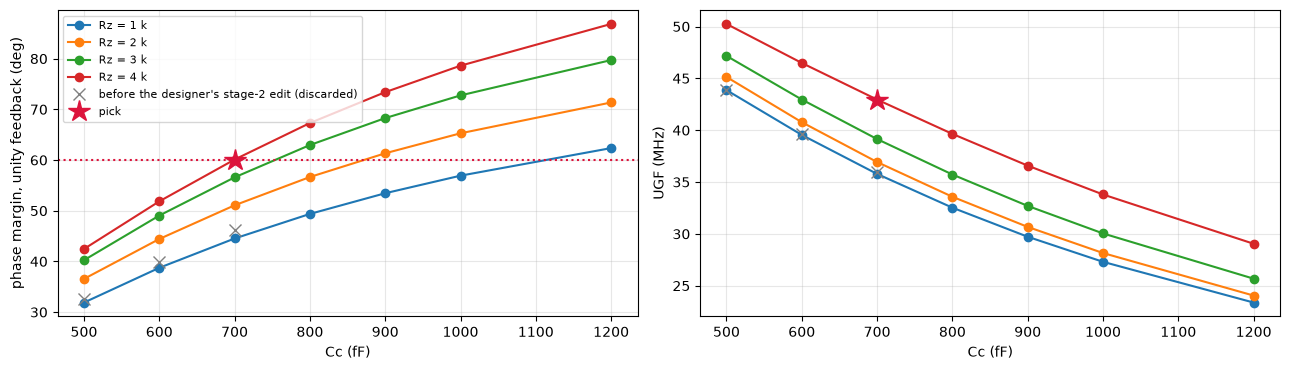

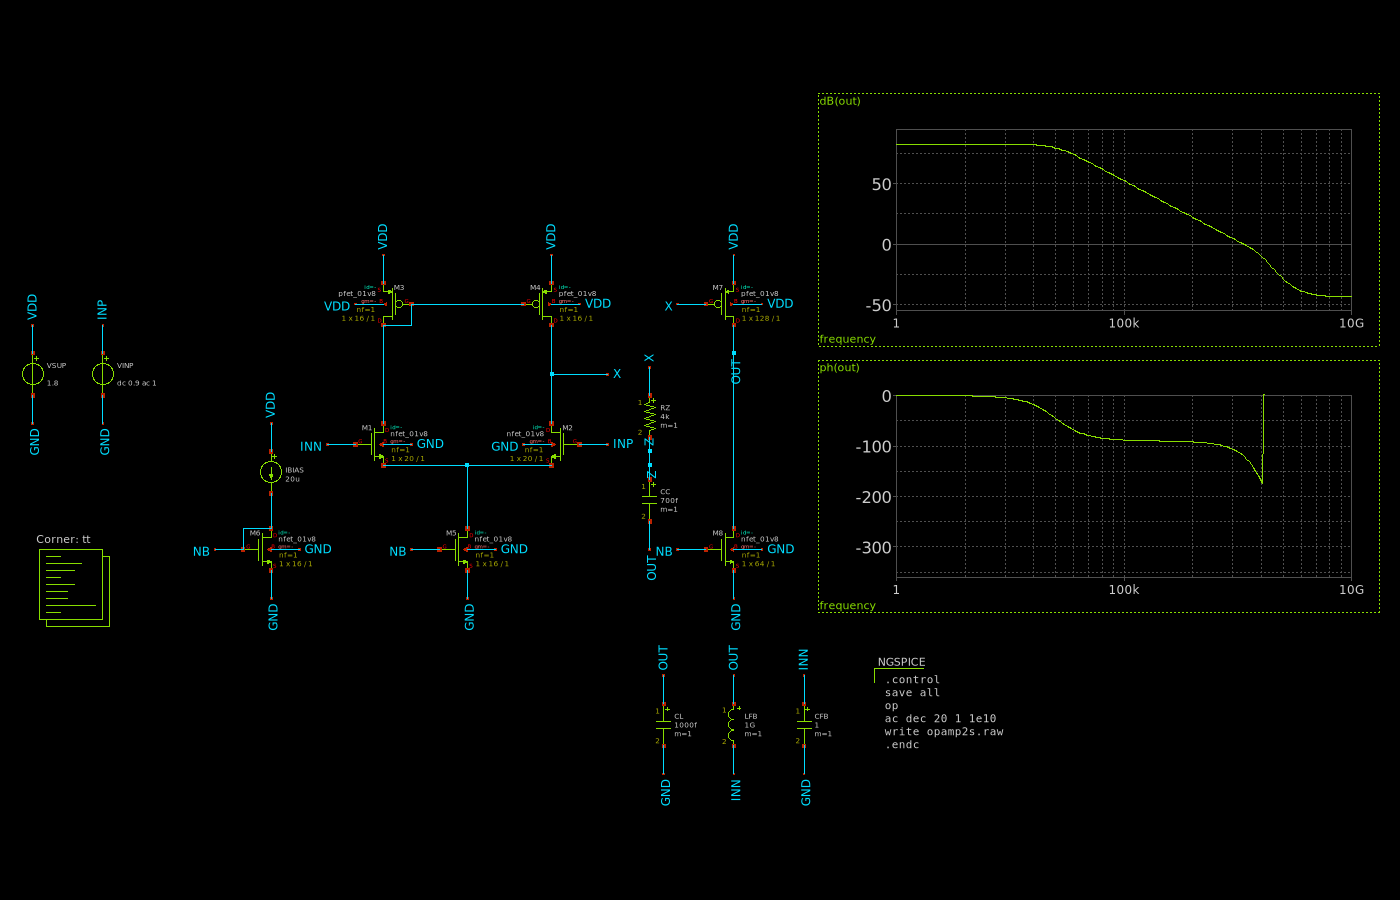

In [14]:
restart = []
for k, cc in enumerate((500, 600, 700, 800, 900, 1000)):
    if k == 2:
        designer.interrupts.send("Phase margin at least 60 deg with the smallest Cc; keep Rz between 1k and 4k",
                                 selection={"xschem": ["CC", "RZ"]}).check()
    r, pt = pm_point(cc, 2)
    if pt is None:
        break
    restart.append(pt)
print(r.status, "-", r.error)
inst = [i for i in r.extra["interrupts"] if i["kind"] == "instruction"][0]
print('  #%d instruction: "%s"  selection %s' % (inst["id"], inst["message"], inst["selection"]))
vd.interrupts.ack("all", note="target: PM >= 60 deg, smallest Cc, Rz 1k-4k").check()

grid = []
for rz in (1, 2, 3, 4):
    for cc in (500, 600, 700, 800, 900, 1000, 1200):
        r, pt = pm_point(cc, rz)
        r.check()
        grid.append(pt)
ok = [p for p in grid if p["pm_deg"] >= 60]
pick = min(ok, key=lambda p: (p["cc_ff"], -p["ugf_mhz"]))
print("%d points; %d meet PM >= 60 deg; pick Cc %d fF, Rz %gk: UGF %.1f MHz, PM %.1f deg" % (
    len(grid), len(ok), pick["cc_ff"], pick["rz_k"], pick["ugf_mhz"], pick["pm_deg"]))
pm_point(pick["cc_ff"], pick["rz_k"])[0].check()
final2 = vd.sim.xschem(nodes=("out",)).check().result["raw_files"][0]["plots"][-1]["nodes"]["out"]   # with graphs
op = vd.sim.op().check().result
vd.interrupts.plan(done=3).check()
b_final = vd.history.list(1).check().result["steps"][-1]["step"]
print("final:", stage2(), "| gain %.1f dB, UGF %.1f MHz, PM %.1f deg | bias warnings: %s" % (
    final2["dc_gain_db"], final2["ugf_hz"] / 1e6, 180 + final2["phase_at_ugf_deg"], op["warnings"] or "none"))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for rz in (1, 2, 3, 4):
    row = [p for p in grid if p["rz_k"] == rz]
    axs[0].plot([p["cc_ff"] for p in row], [p["pm_deg"] for p in row], "o-", label="Rz = %d k" % rz)
    axs[1].plot([p["cc_ff"] for p in row], [p["ugf_mhz"] for p in row], "o-")
for ax, key in ((axs[0], "pm_deg"), (axs[1], "ugf_mhz")):
    ax.plot([p["cc_ff"] for p in stale], [p[key] for p in stale], "x", c="gray", ms=9,
            label="before the designer's stage-2 edit (discarded)" if key == "pm_deg" else None)
    ax.plot(pick["cc_ff"], pick[key], "*", c="crimson", ms=16, label="pick" if key == "pm_deg" else None)
    ax.set_xlabel("Cc (fF)"); ax.grid(alpha=.3)
axs[0].axhline(60, ls=":", c="crimson"); axs[0].set_ylabel("phase margin, unity feedback (deg)")
axs[1].set_ylabel("UGF (MHz)"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(Image(x.screenshot(os.path.join(ROOT, "runs", "opamp2s_final.png")).check().result["local_path"], width=900))

> **Designer's view.** The designer pointed at two parts and wrote one sentence; the agent ran the
> dozens of simulations and reports one pick with its margin. The grey crosses are the points measured
> on the old second stage: kept out of the decision, but visible.

## B4. The rebuild guard on the larger design
After the sweep, rebuilding the op amp "cleanly" from the script would be tempting for an agent. The
designer has edited this file, so it is refused.

In [15]:
rg = x.new_schematic(OPAMP, replace=True)
print(rg.status, "-", rg.error)
print("hint:", rg.extra.get("hint"))
print("design unchanged:", stage2())

DENIED - the designer edited /foss/designs/viaduct/xschem/opamp2s_20261029_110522.sch (history steps [673]); rebuilding it with new_schematic replace=true would erase their work
hint: change the open schematic with set_props / place / wire instead; rebuild only if the designer agrees (force_rebuild=true)


design unchanged: M7 W=128  M8 W=64  CC=700f  RZ=4k


## B5. Back and forward in the time scroll
The designer compares with the op amp as the agent first built it (restore to the B1 checkpoint), then
returns to the final design (restore forward). Each restore interrupts the agent with every element that
changed under it.

In [16]:
def restore_and_report(step):
    res = designer.history.restore(step).check().result
    r = x.set_props("CL", value="1000f")      # the agent's next edit
    irq = [i for i in r.extra["interrupts"] if i["kind"] == "restore"][0]
    print("restored %d as step %d -> agent: %s | %s" % (step, res["new_step"], r.status, irq["message"]))
    for inst, ch in irq["changes"]["changed"].items():
        print("  %s: %s" % (inst, ", ".join("%s %s -> %s" % (p, a, b) for p, (a, b) in ch.items())))
    vd.interrupts.ack("all", note="continuing from restored step %d" % step).check()
    print("  now:", stage2())
    return res, irq
res_back, irq_back = restore_and_report(b_ref)
print()
res_fwd, irq_fwd = restore_and_report(b_final)

restored 669 as step 708 -> agent: INTERRUPTED | the designer restored step 669; continue from it
  CC: value 700f -> 500f
  M7: W 128 -> 96
  M8: W 64 -> 48
  RZ: value 4k -> 2k


  now: M7 W=96  M8 W=48  CC=500f  RZ=2k



restored 706 as step 710 -> agent: INTERRUPTED | the designer restored step 706; continue from it
  CC: value 500f -> 700f
  M7: W 96 -> 128
  M8: W 48 -> 64
  RZ: value 2k -> 4k


  now: M7 W=128  M8 W=64  CC=700f  RZ=4k


## B6. The time scroll of part B, and what was checked
Every step above is in the time scroll with a screenshot. The first figure shows the key steps as the
designer sees them in the cockpit; the second draws every step of part B by who made it, with each step
linked to the one it came from, so the restores show up as jumps back and forward.

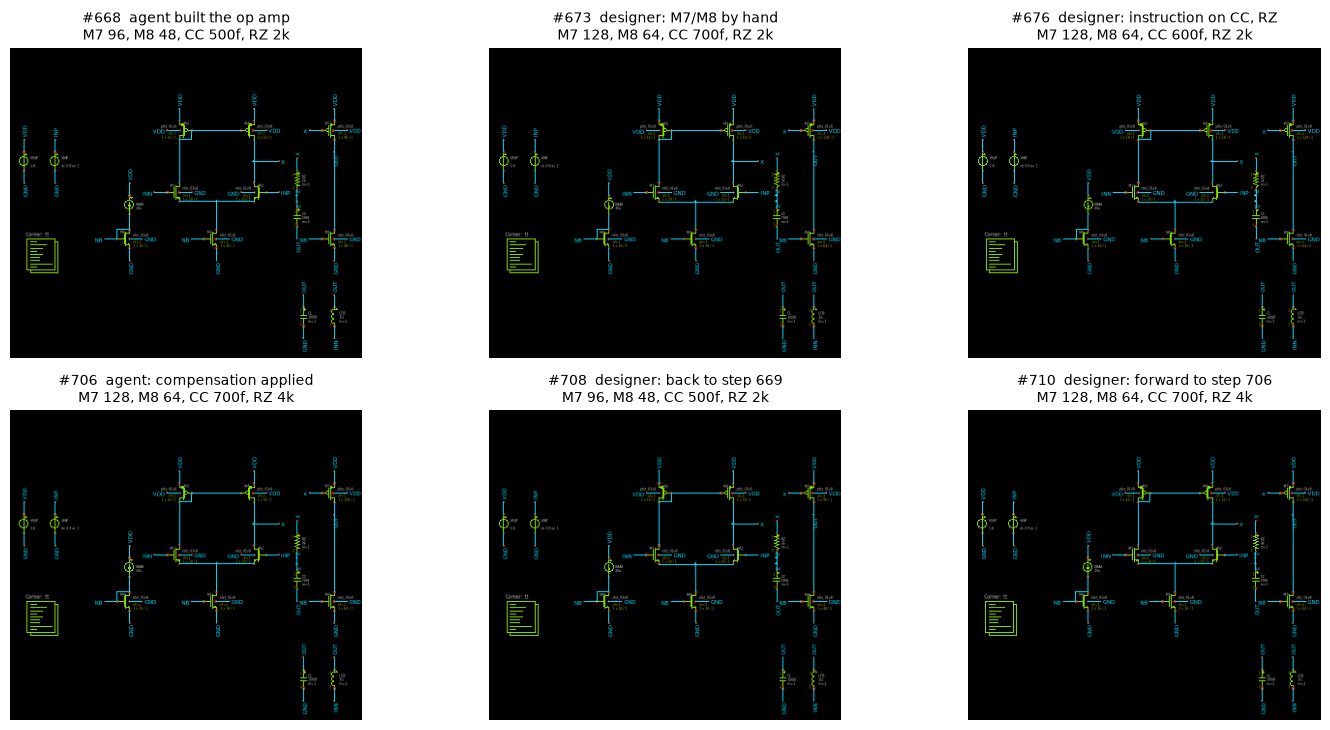

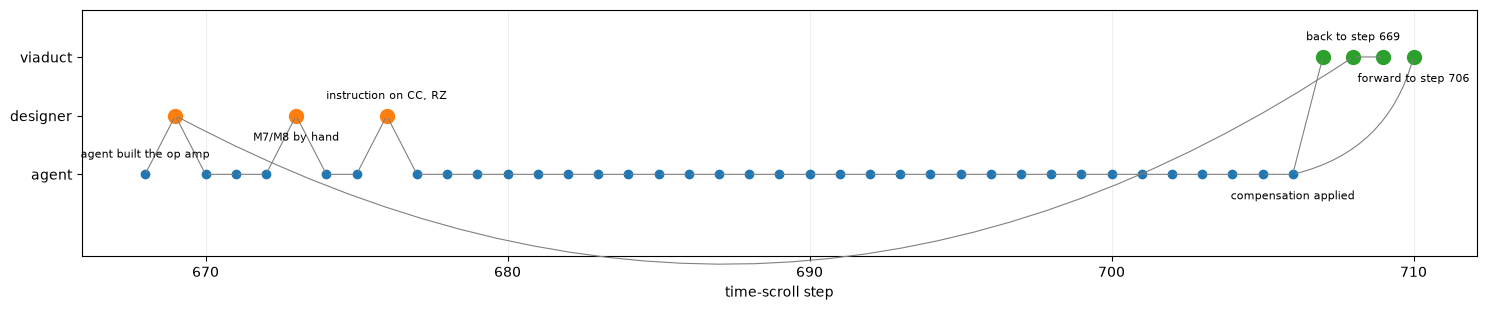

43 steps in part B's time scroll (36 by the agent, 3 by the designer, 4 by Viaduct)
PASS  hand edit of two devices detected; both in the diff
PASS  the agent's edit was refused and changed nothing
PASS  instruction delivered with the two-part selection
PASS  instruction applied on top of the designer's stage 2
PASS  rebuild of the edited op amp denied
PASS  restore back reports M7, M8, CC and RZ
PASS  restore forward brings the final design back
PASS  every step of part B has a screenshot


In [17]:
h = vd.history.list(400).check().result
steps = [s for s in h["steps"] if s["step"] >= b_start]
by_step = {s["step"]: s for s in steps}
thumb = lambda n: os.path.join(h["dir"], "steps", "%04d" % n, "xschem.png")
def at_step(n):                     # M7/M8 widths, CC and RZ saved with step n (a restore step: its target)
    f = os.path.join(h["dir"], "steps", "%04d" % n, "schematic.sch")
    if not os.path.exists(f):
        return at_step(by_step[n]["parent"])
    txt = open(f).read()
    get = lambda inst, k: re.search(r"\b%s=(\S+)" % k, re.search(r"\{name=%s\b([^}]*)\}" % inst, txt).group(1)).group(1)
    return "M7 %s, M8 %s, CC %s, RZ %s" % (get("M7", "W"), get("M8", "W"), get("CC", "value"), get("RZ", "value"))
first_of = lambda kind, actor: next(s["step"] for s in steps if s["kind"] == kind and s["actor"] == actor)
key = [(b_start, "agent built the op amp"),
       (first_of("hand_edit", "designer"), "designer: M7/M8 by hand"),
       (next(s["step"] for s in steps if (s["label"] or "").startswith("interrupt: Phase margin")), "designer: instruction on CC, RZ"),
       (b_final, "agent: compensation applied"),
       (res_back["new_step"], "designer: back to step %d" % b_ref),
       (res_fwd["new_step"], "designer: forward to step %d" % b_final)]
fig, axs = plt.subplots(2, 3, figsize=(15, 7.4))
for ax, (n, title) in zip(axs.flat, key):
    src = thumb(n if os.path.exists(thumb(n)) else by_step[n]["parent"])     # a restore step shows its target
    img = plt.imread(src)
    ax.imshow(img[int(.12 * img.shape[0]):int(.92 * img.shape[0]), :int(.57 * img.shape[1])])   # the circuit, not the graphs
    ax.set_title("#%d  %s\n%s" % (n, title, at_step(n)), fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

lane = {"agent": 0, "designer": 1, "viaduct": 2}
color = {"agent": "tab:blue", "designer": "tab:orange", "viaduct": "tab:green"}
fig, ax = plt.subplots(figsize=(15, 3.2))
for s in steps:
    p = by_step.get(s["parent"])
    if p:
        ax.annotate("", (s["step"], lane[s["actor"]]), (p["step"], lane[p["actor"]]),
                    arrowprops=dict(arrowstyle="-", color="gray", lw=.8,
                                    connectionstyle="arc3,rad=%g" % (.3 if s["kind"] == "restore" else 0)))
    ax.plot(s["step"], lane[s["actor"]], "o", c=color[s["actor"]], ms=6 if s["kind"] == "edit" else 10)
for k, (n, title) in enumerate(key):            # labels alternate above and below the lane
    ax.annotate(title.split(":")[-1].strip(), (n, lane[by_step[n]["actor"]]), (0, 12 if k % 2 == 0 else -18),
                textcoords="offset points", ha="center", fontsize=8)
ax.set_yticks(list(lane.values())); ax.set_yticklabels(list(lane)); ax.set_ylim(-1.4, 2.8)   # room for the restore arcs
ax.set_xlabel("time-scroll step"); ax.grid(axis="x", alpha=.2); plt.tight_layout(); plt.show()

checks = [
    ("hand edit of two devices detected; both in the diff", set(hand["changes"]["changed"]) == {"M7", "M8"}),
    ("the agent's edit was refused and changed nothing", r_hand.status == "INTERRUPTED" and cc_after == cc_before),
    ("instruction delivered with the two-part selection", inst["selection"].get("xschem") == ["CC", "RZ"]),
    ("instruction applied on top of the designer's stage 2", (val("M7", "W"), val("M8", "W")) == ("128", "64")),
    ("rebuild of the edited op amp denied", rg.status == "DENIED"),
    ("restore back reports M7, M8, CC and RZ", {"M7", "M8", "CC", "RZ"} <= set(irq_back["changes"]["changed"])),
    ("restore forward brings the final design back", val("CC", "value") == "%gf" % pick["cc_ff"]),
    ("every step of part B has a screenshot", all(os.path.exists(thumb(s["step"])) for s in steps if s["kind"] != "restore")),
]
print("%d steps in part B's time scroll (%d by the agent, %d by the designer, %d by Viaduct)" % (
    len(steps), *[sum(s["actor"] == a for s in steps) for a in ("agent", "designer", "viaduct")]))
for name, passed in checks:
    print("%s  %s" % ("PASS" if passed else "FAIL", name))

**Part B in one sentence:** on a design with twice the parts and an agent in the middle of a sweep,
a two-device hand edit, an instruction about two parts, the rebuild guard and a restore back and forward
all reached the agent with the exact change, and the agent kept no result from the circuit the designer had
replaced.

---
# Part C. A T-coil bandwidth extension: layout and EM in the loop
The layout side of the flow: the agent edits a T-coil PCell in the designer's KLayout window, runs EM
and DRC on it, and closes the loop with the circuit simulation. The designer sets the target and judges
the extracted result; every number comes back with its run ID and is written into the PCell.

## C1. The layout tap: a T-coil PCell, edited through the API
`place_tcoil` and `set_pcell_params` run inside KLayout; the screenshot is KLayout's own rendering.

{'metalWidth': 4.0, 'area': 8000.0, 'actualTurnSpacing': 2.655, 'resultStatus': 'NOT_RUN'} [[-39.33, -50.1], [39.33, 39.33]]


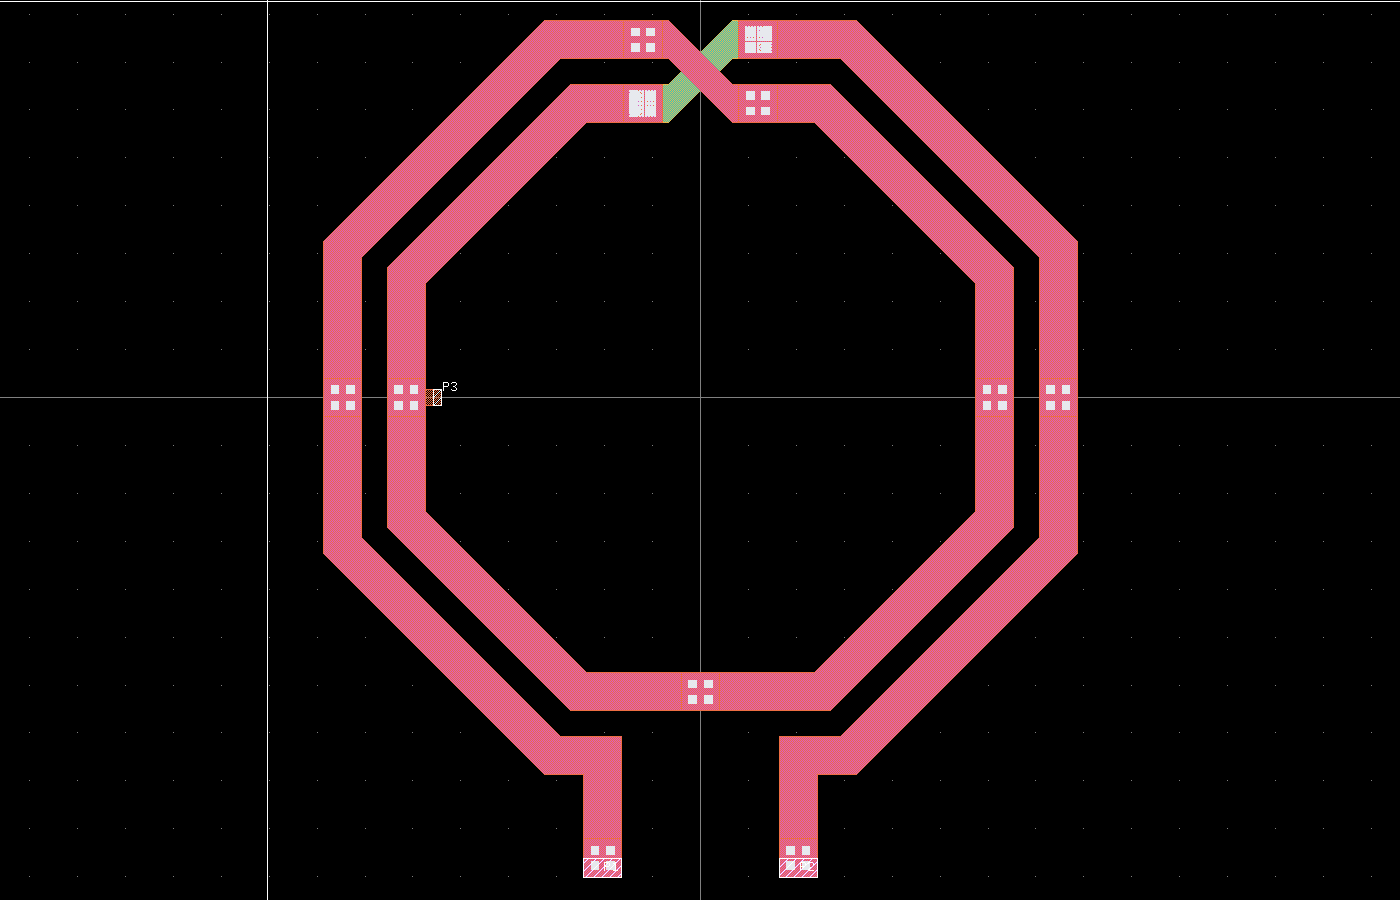

In [18]:
vd.klayout.new_layout("TCOIL_NB").check()
coil = vd.klayout.place_tcoil("DUT", params={"metalWidth": 4.0, "area": 8000.0}).check().result
print({k: coil["params"][k] for k in ("metalWidth", "area", "actualTurnSpacing", "resultStatus")}, coil["bbox_um"])
display(Image(vd.klayout.screenshot().check().result["local_path"], width=520))

## C2. EM and DRC of that coil
FastHenry gives L1/L2/R/Q/K between the ports P1-P3 and P2-P3; FasterCap gives the parasitic
capacitances; the SKY130 KLayout DRC deck checks the layout. Results go back into the PCell's
read-only fields together with the run ID.

In [19]:
em = vd.em.fasthenry({"metalWidth": 4.0, "area": 8000.0}, freqs_hz=[1e9, 5e9, 1e10, 2e10]).check().result
print("FastHenry run", em["run_id"])
for r in em["results"]:
    print("%5.1f GHz  L1 %.4f nH  L2 %.4f nH  K1 %+.3f  Q1 %5.2f  Q2 %5.2f" % (
        r["frequency_hz"] / 1e9, r["L1_nH"], r["L2_nH"], r["K1"], r["Q1"], r["Q2"]))
vd.klayout.annotate("DUT", em["annotation"], "FASTHENRY " + em["run_id"]).check()
cap = vd.em.fastercap({"metalWidth": 4.0, "area": 8000.0}).check().result
print("FasterCap run %s: between halves %.1f fF, halves to substrate %.1f / %.1f fF" % (
    cap["run_id"], cap["C_AB_fF"], cap["C_A_gnd_fF"], cap["C_B_gnd_fF"]))
tdrc = vd.verify.drc().check().result
print("DRC run %s (%s, release %s): %d rules checked, %d violations" % (
    tdrc["run_id"], os.path.basename(tdrc["deck"]), tdrc["deck_release"], tdrc["rules_checked"], tdrc["violations"]))

FastHenry run 20261029_110754_9124
  1.0 GHz  L1 0.2072 nH  L2 0.1148 nH  K1 -0.332  Q1  0.97  Q2  0.78
  5.0 GHz  L1 0.2064 nH  L2 0.1142 nH  K1 -0.333  Q1  4.56  Q2  3.67
 10.0 GHz  L1 0.2048 nH  L2 0.1132 nH  K1 -0.336  Q1  8.07  Q2  6.55
 20.0 GHz  L1 0.2022 nH  L2 0.1117 nH  K1 -0.341  Q1 12.93  Q2 10.60


FasterCap run 20261029_110800_3fae: between halves 13.9 fF, halves to substrate 27.9 / 19.9 fF


DRC run 20261029_110829_182e (sky130A_mr.drc, release 2024.2.11_01.09): 256 rules checked, 0 violations


## C3. Closed loop: T-coil bandwidth extension
1. build a 50-ohm cascode driver with C_L = 150 fF at the coil tap in xschem, through the API;
2. baseline without coil; 3. ideal T-coil found by a 150-point ngspice sweep;
4. size the coil (`area`) against FastHenry to the optimizer's series inductance;
5. final EM + FasterCap, results into the PCell; 6. back-annotate and re-simulate; 7. report.

> **Designer's view.** The bandwidth target, the coil's geometry limits and the acceptance of the
> extracted result are the designer's; the loop of sweeps, EM runs and re-simulations is the agent's.

In [20]:
import tcoil_amp_closed_loop as loop
report, rdir = loop.run(vd)

[11:08:33] 1 xschem: building /foss/designs/viaduct/xschem/tcoil_amp.sch live


[11:08:33] 2 ngspice: baseline (no coil)


[11:08:37]    baseline: gain -4.17 dB, f3dB 16.3GHz


[11:08:37] 3 optimizer: ideal symmetric T-coil (L1=L2, k, C_B), peaking <= 1.00 dB


[11:08:41]    150 points in 4s; best: L1=L2=169pH k=0.3 C_B=20fF -> f3dB 40.6GHz (peaking 0.01 dB); series L target 439pH


...

[11:09:47]    L+C extracted, P1 at drain         gain  -3.99 dB  f3dB   23.3GHz  peaking 0.00 dB  (x1.43)


[11:09:47]    L+C extracted, P2 at drain         gain  -3.90 dB  f3dB   26.5GHz  peaking 0.00 dB  (x1.63)


[11:09:47]    L+C extracted + C_B extra 20fF     gain  -3.90 dB  f3dB   29.9GHz  peaking 0.00 dB  (x1.84)


[11:09:51] 7 report


[11:09:51] done in 78s -> /foss/designs/viaduct/runs/closedloop_20261029_110951


case                                          f3dB   x base  peaking
baseline: no T-coil                         16.3G     1.00    0.00dB
ideal T-coil (optimizer)                    40.6G     2.50    0.01dB
extracted, P1 at drain                      27.9G     1.72    0.00dB
extracted, P2 at drain                      31.0G     1.91    0.10dB
extracted + C_B=30fF                        34.8G     2.14    0.41dB
L+C extracted, P1 at drain                  23.3G     1.43    0.00dB
L+C extracted, P2 at drain                  26.5G     1.63    0.00dB
L+C extracted + C_B extra 20fF              29.9G     1.84    0.00dB
checks: all within the T-coil limit


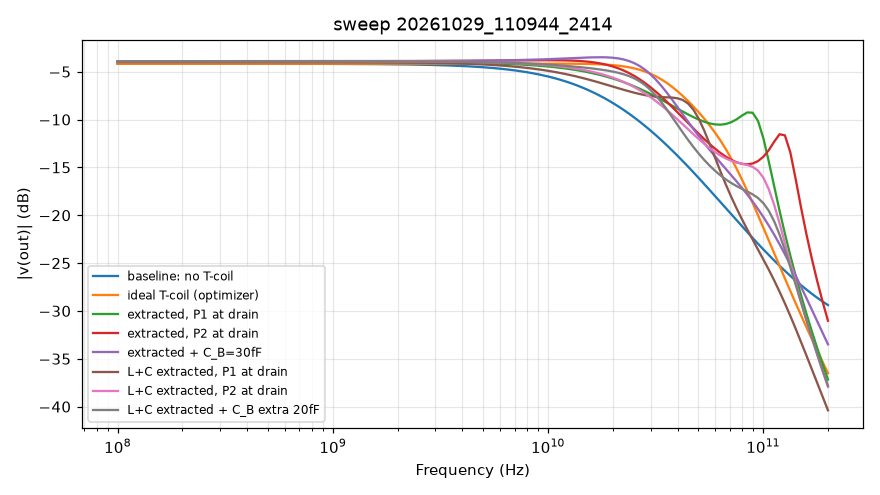

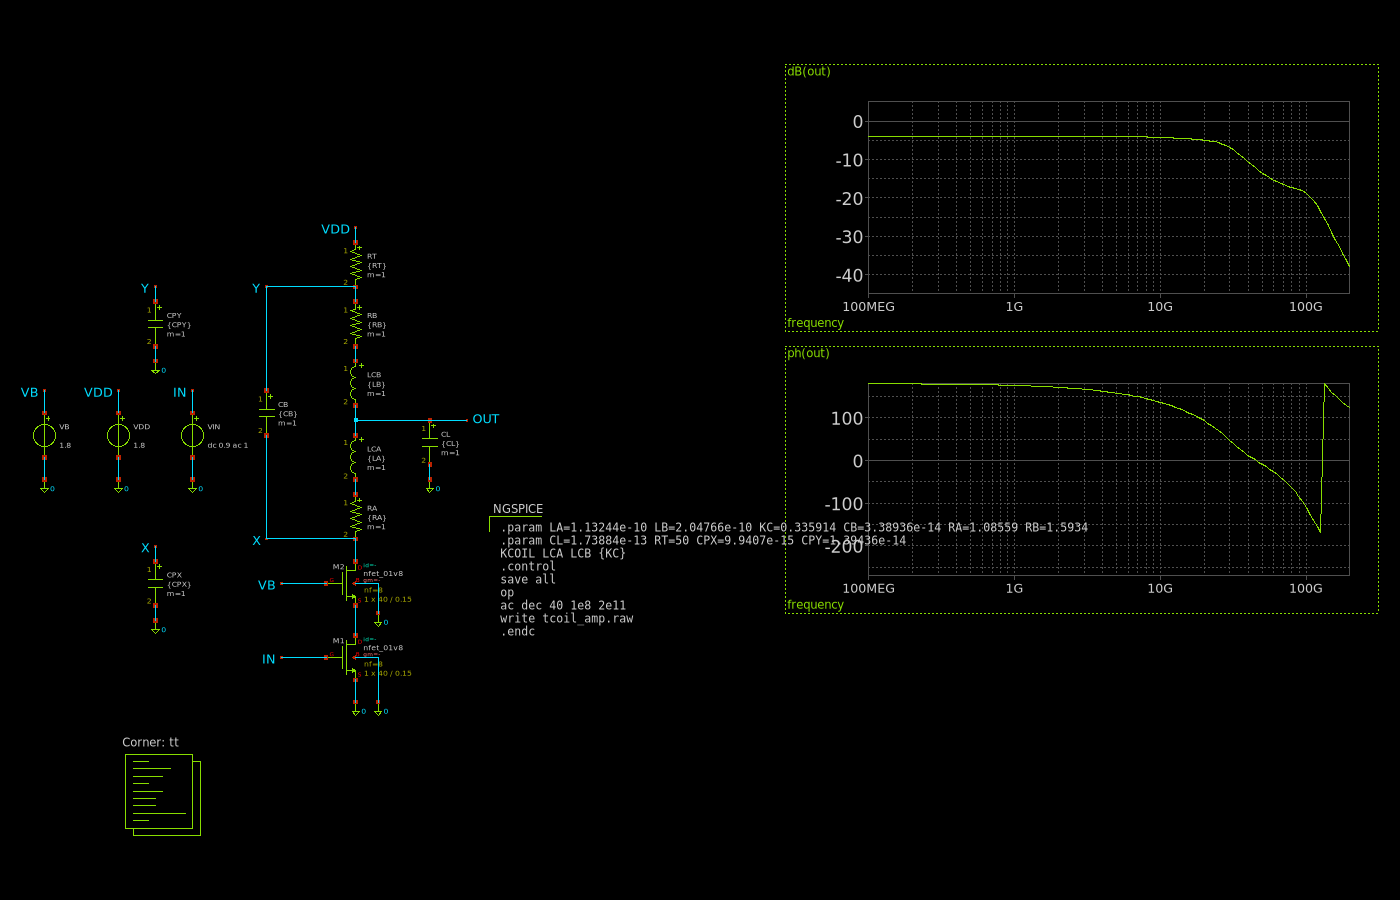

In [21]:
rows = report["compare"]
base = rows[0]["f3db_hz"]
print("%-40s %9s %8s %8s" % ("case", "f3dB", "x base", "peaking"))
for q in rows:
    print("%-40s %7.1fG %8.2f %7.2fdB" % (q["label"], q["f3db_hz"] / 1e9, q["f3db_hz"] / base, q["peaking_db"]))
print("checks:", report["checks"] or "all within the T-coil limit")
display(Image(report["compare_plot"][0], width=760))
display(Image(report["runs"]["schematic_with_graphs"], width=760))

## C4. Full-wave cross-check (Palace FEM)
The coil plus a met1 ground frame and fingers, simulated full-wave with gds2palace + AWS Palace
(lossy substrate, dielectrics) and, on the identical structure, with FastHenry. A run takes
20-50 minutes, so the archived result (docs/fullwave) is shown; set `RUN_FULLWAVE = True` to re-run.

GHz   L1 Palace/FastHenry   L2 Palace/FastHenry   Q1 Palace/FastHenry
   1   0.3131 / 0.2867       0.2109 / 0.1950        0.38 /  0.29
   5   0.2740 / 0.2825       0.1859 / 0.1926        1.48 /  1.39
  10   0.2675 / 0.2789       0.1806 / 0.1906        2.72 /  2.65
  20   0.2709 / 0.2754       0.1798 / 0.1883        4.90 /  4.88
  30   0.2834 / 0.2732       0.1830 / 0.1869        6.59 /  6.84
  40   0.3058 / 0.2718       0.1893 / 0.1858        7.74 /  8.61
  50   0.3438 / 0.2706       0.1996 / 0.1850        8.24 / 10.25


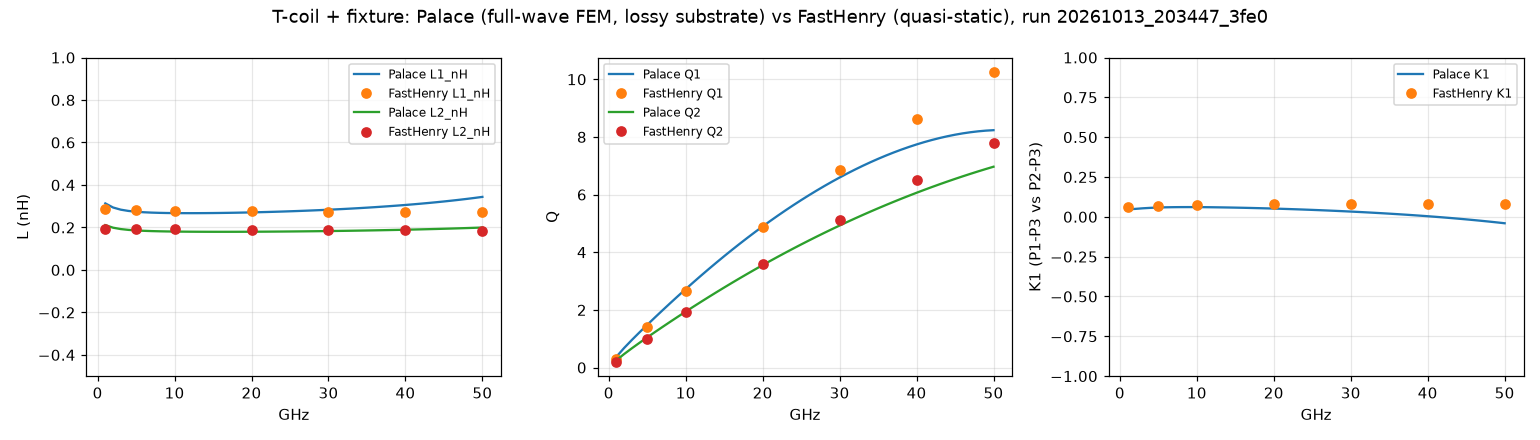

In [22]:
RUN_FULLWAVE = False
if RUN_FULLWAVE:
    fw = vd.em.palace({"metalWidth": 4.0, "area": 8000.0}).check().result
    rows, png = fw["summary"]["rows"], fw["images"][0]
else:
    arch = json.load(open(os.path.join(ROOT, "docs", "fullwave", "results_20261013.json")))["mesh_2.2um"]
    rows, png = arch["summary"]["rows"], os.path.join(ROOT, "docs", "fullwave", "palace_vs_fasthenry.png")
print("GHz   L1 Palace/FastHenry   L2 Palace/FastHenry   Q1 Palace/FastHenry")
for r in rows:
    print("%4.0f   %.4f / %.4f       %.4f / %.4f       %5.2f / %5.2f" % (
        r["GHz"], r["L1_nH"][0], r["L1_nH"][1], r["L2_nH"][0], r["L2_nH"][1], r["Q1"][0], r["Q1"][1]))
display(Image(png, width=900))

## C5. Why a T-coil extends bandwidth (interactive)
An ideal symmetric T-coil (L1 = L2 = L, coupling k, bridging C_B) between the driver node X and the
termination R, with the load C at the tap. The driver is an ideal current source with its own C_d at X.
Nodal analysis with numpy; the sliders need ipywidgets. This idealized model reproduces the 16.3 GHz baseline of C3 exactly, but gives about 2.96x at the optimizer's point instead of 2.50x: here the driver is an ideal current source with a fixed C_d, while C3 simulates the real cascode transistors.

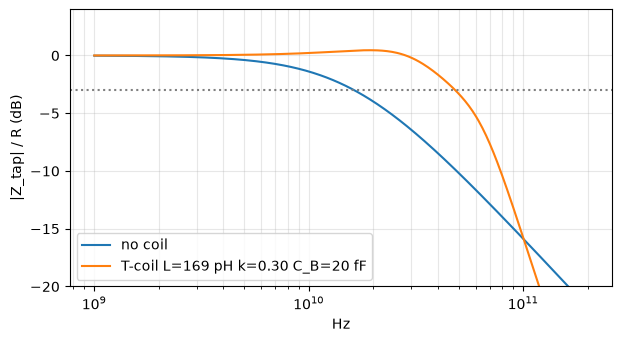

interactive(children=(FloatSlider(value=0.3, description='k', max=0.8, step=0.05), IntSlider(value=169, descri…

In [23]:
def tcoil_z(f, R=50.0, C=150e-15, Cd=45e-15, L=169e-12, k=0.3, Cb=20e-15):
    w = 2 * np.pi * f
    out = []
    for wi in w:
        s = 1j * wi
        if L <= 0:                      # no coil: one node, R || (C + Cd)
            out.append(1 / (1 / R + s * (C + Cd)))
            continue
        Lm = np.array([[L, k * L], [k * L, L]])
        G = np.linalg.inv(s * Lm)       # branch currents from branch voltages
        A = np.array([[1, -1, 0], [0, 1, -1]])   # branches X->T, T->Y over nodes X, T, Y
        Y = A.T @ G @ A
        Y += np.diag([s * Cd, s * C, 1 / R])
        Y += s * Cb * np.array([[1, 0, -1], [0, 0, 0], [-1, 0, 1]])
        v = np.linalg.solve(Y, np.array([1, 0, 0]))
        out.append(v[1])                # voltage at the tap per unit drive current
    return np.array(out)
f = np.logspace(9, 11.3, 400)
def show(k=0.3, L_pH=169, Cb_fF=20):
    plt.figure(figsize=(7, 3.6))
    z0 = tcoil_z(f, L=0)
    zt = tcoil_z(f, L=L_pH * 1e-12, k=k, Cb=Cb_fF * 1e-15)
    for z, lab in ((z0, "no coil"), (zt, "T-coil L=%g pH k=%.2f C_B=%g fF" % (L_pH, k, Cb_fF))):
        g = 20 * np.log10(np.abs(z) / 50)
        plt.semilogx(f, g, label=lab)
    plt.axhline(-3, ls=":", c="gray"); plt.ylim(-20, 4); plt.grid(True, which="both", alpha=.3)
    plt.xlabel("Hz"); plt.ylabel("|Z_tap| / R (dB)"); plt.legend(); plt.show()
show()      # the optimizer's ideal point from C3
try:        # sliders when run interactively in Jupyter
    from ipywidgets import interact
    interact(show, k=(0.0, 0.8, 0.05), L_pH=(50, 400, 10), Cb_fF=(0, 60, 2))
except ImportError:
    pass

---
## Who did what
| Step | Agent (through Viaduct) | Designer |
|---|---|---|
| A2 hand edit | its next edit refused with the exact change; continues from the designer's M5 | lengthens M5 in the window, no command typed |
| A3 instruction | reads the message and the selection, applies it to M1/M2 on top of the designer's edit, checks the bias | selects the pair, writes one sentence |
| A4 pause | edits held, reads still allowed, plan kept | pauses, looks, resumes |
| A5 rebuild guard | `DENIED`, edits in place instead | nothing: their work is protected |
| A6 restore | told every change that was reverted, re-plans | goes back to any step of the time scroll |
| B1 two-stage op amp | 68 edits in one batch, connectivity, AC and bias, a plan | topology and specification |
| B2 hand edit mid-sweep | refused with both devices' changes; discards the sweep points of the old circuit | raises the second-stage current (M7, M8) by hand |
| B3 instruction | a 28-point Cc / Rz sweep against the designer's target, the pick and its margin | selects CC and RZ, sets the target in one sentence |
| B4, B5 guard, restore | `DENIED` on a rebuild; told every element that a restore changed | compares with an earlier step, goes back and forward |
| C T-coil | PCell edits in KLayout, FastHenry / FasterCap / DRC, closed-loop sizing, full-wave check | bandwidth target, coil limits, accepts the extracted result |


---
## Limitations and next steps
**Designer in the loop (part A)**
* A hand edit is seen at the agent's next Viaduct request; an agent that only simulates for a long time
  sees it late (instructions and pauses are not affected). Hooks in the agent host would close that gap.
* KLayout hand edits are reported as "layout changed", without a per-shape diff yet.

**Op amp (part B)**
* Viaduct tells the agent exactly what changed; deciding which of its own results that makes stale (the
  sweep points in B2) is still the agent's job.
* Schematic and simulation only; the op amp's layout, parasitic extraction and post-layout simulation are
  not part of this notebook. The next IIC-OSIC-TOOLS image (2026.10) ships KLayout-PEX 0.6.8 with FEM
  plugins; a `verify pex` step and a pre- / post-layout comparison are next.
* The phase margin quoted is the one of the amplifier as a unity-gain buffer, where the loop gain equals
  the open-loop gain measured here; the op amp is checked at the tt corner only.

**T-coil (part C)**
* The extracted coil is a lumped model: FastHenry is magneto-quasi-static (no substrate loss, no
  capacitance) and FasterCap uses one homogeneous dielectric with the substrate as a ground plane.
  The full-wave check (C4) confirms FastHenry's L and Q to within a few percent up to ~25 GHz and shows
  L rising / Q dropping above it; a coil-only (de-embedded) full-wave model is not used in the loop yet.
  The substrate resistivity (10 ohm*cm) is an assumption.
* The coil's tap is off-centre (L1 about 1.8 x L2), so a symmetric ideal optimum cannot be matched exactly.
* DRC uses the community SKY130 KLayout deck (no density rules), not a foundry signoff deck.

**References.** xschem; ngspice; KLayout and the SKY130 KLayout DRC and LVS decks; the SKY130 `skywater130`
KLayout PCells; FastHenry2 and FasterCap (FastFieldSolvers); AWS Palace and gds2palace; IIC-OSIC-TOOLS
(JKU); virtuoso-bridge; skillbridge; KlayoutClaw; klive; S. Galal and B. Razavi, "Broadband ESD protection
circuits in CMOS technology", IEEE JSSC 38(12), 2003 (T-coil design); P. R. Gray et al., *Analysis and
Design of Analog Integrated Circuits* (OTA design).

In [24]:
print(json.dumps({
    "designer_in_the_loop": {"first_step": start_step, "checkpoint": ref, "restored_as": res["new_step"]},
    "op_amp": {"schematic": OPAMP, "sim_run": amp["sim_run"], "first_step": b_start, "final_step": b_final,
               "pick": pick, "checks_passed": sum(ok for _, ok in checks), "checks": len(checks)},
    "tcoil": {"report_dir": str(rdir), "runs": {k: v for k, v in report["runs"].items() if "screenshot" not in k}}}, indent=2))

{
  "designer_in_the_loop": {
    "first_step": 658,
    "checkpoint": 659,
    "restored_as": 666
  },
  "op_amp": {
    "schematic": "/foss/designs/viaduct/xschem/opamp2s_20261029_110522.sch",
    "sim_run": "20261029_110523_f715",
    "first_step": 668,
    "final_step": 706,
    "pick": {
      "cc_ff": 700,
      "rz_k": 4,
      "ugf_mhz": 42.952601641843465,
      "pm_deg": 60.098
    },
    "checks_passed": 8,
    "checks": 8
  },
  "tcoil": {
    "report_dir": "/foss/designs/viaduct/runs/closedloop_20261029_110951",
    "runs": {
      "baseline": "20261029_110833_d2a8",
      "optimizer": "20261029_110837_9ed2",
      "em_final": "20261029_110854_ffc5",
      "cap_final": "20261029_110900_7d32",
      "lc_cb_sweep": "20261029_110941_86da",
      "compare": "20261029_110944_2414",
      "cb_sweep": "20261029_110934_e2b8",
      "live_sim": "20261029_110948_943a",
      "schematic_with_graphs": "/foss/designs/viaduct/runs/xschem_20261029_110951.png"
    }
  }
}


## Acknowledgement

This work is supported by the Agency for Science, Technology and Research (A*STAR), Singapore under the Semiconductor RIE Flagship Programme (Integrated Circuit Design & Systems), grant No. H26-MSE1535.

We thank the maintainers and contributors of
[IIC-OSIC-TOOLS](https://github.com/iic-jku/iic-osic-tools) for providing the
open-source IC design environment that supports Viaduct's development and demonstrations.
